# Exercise 2 — Non-Linearity in 5D

Goal: compare two 5-dimensional, 2-class datasets — one where a straight line (hyperplane) can separate the classes, and one where it fundamentally can't, even though the classes ARE separable by a different (non-linear) rule.

## Setup

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from sklearn.decomposition import PCA

rng = np.random.default_rng(42)
N = 500

## Dataset I — two ordinary Gaussians in 5D
Class A centered at the origin, Class B centered 1.5 units away on every axis. Each has its own covariance matrix (some correlated dimensions). Because the means are genuinely far apart, this is the "easy" case.

In [2]:
mu_A = np.array([0.0, 0.0, 0.0, 0.0, 0.0])
Sigma_A = np.array([
    [1.0, 0.8, 0.1, 0.0, 0.0],
    [0.8, 1.0, 0.3, 0.0, 0.0],
    [0.1, 0.3, 1.0, 0.5, 0.0],
    [0.0, 0.0, 0.5, 1.0, 0.2],
    [0.0, 0.0, 0.0, 0.2, 1.0],
])
mu_B = np.array([1.5, 1.5, 1.5, 1.5, 1.5])
Sigma_B = np.array([
    [1.5, -0.7, 0.2, 0.0, 0.0],
    [-0.7, 1.5, 0.4, 0.0, 0.0],
    [0.2, 0.4, 1.5, 0.6, 0.0],
    [0.0, 0.0, 0.6, 1.5, 0.3],
    [0.0, 0.0, 0.0, 0.3, 1.5],
])

class_A = rng.multivariate_normal(mu_A, Sigma_A, size=N)
class_B = rng.multivariate_normal(mu_B, Sigma_B, size=N)
X1 = np.vstack([class_A, class_B])
y1 = np.array([0] * N + [1] * N)

## Dataset II — concentric shells
Here's the trick: both classes are centered at the origin on *average* (no directional bias), but Class C sits close to the origin (radius ~2.0) and Class D sits far from it (radius ~5.0). We build each point as `direction * radius`:

1. Pick a random direction by sampling from a standard normal in 5D and normalizing it to unit length — this gives a uniformly random point on the unit sphere.
2. Pick a radius from a Gaussian centered on 2.0 (core, Class C) or 5.0 (shell, Class D).
3. Multiply direction by radius.

The two classes end up **overlapping in every direction** but **separated in distance from the center** — a shape no straight line can carve apart.

In [3]:
def sample_shell(n, radius_mean, radius_std, rng):
    directions = rng.standard_normal((n, 5))
    directions /= np.linalg.norm(directions, axis=1, keepdims=True)
    radii = rng.normal(radius_mean, radius_std, size=n)
    return directions * radii[:, None]

class_C = sample_shell(N, 2.0, 0.4, rng)  # core
class_D = sample_shell(N, 5.0, 0.4, rng)  # shell
X2 = np.vstack([class_C, class_D])
y2 = np.array([0] * N + [1] * N)

## Figure 4 — PCA projections
We can't plot 5D directly, so PCA compresses each dataset down to its 2 most informative directions (highest variance) for a rough visual. Note PCA is a *linear* technique — it can only ever show linear structure, so if Dataset II still looks separable here, the separation it's showing isn't the radial one (or it's showing it only by accident).

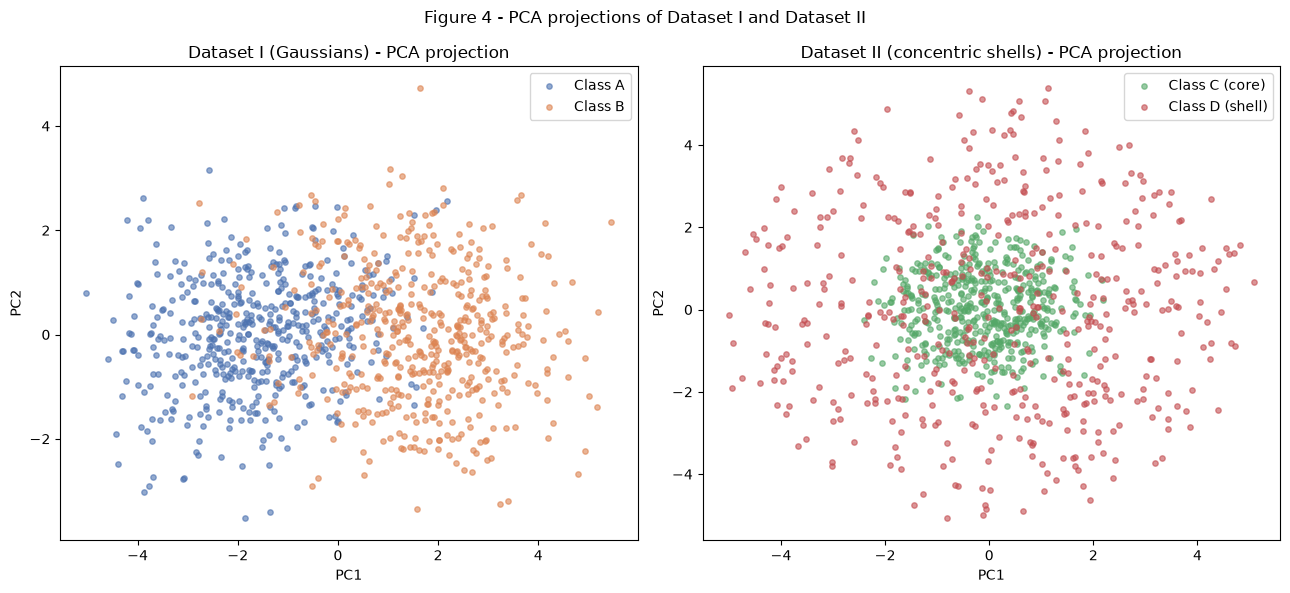

Explained variance (PC1+PC2) - Dataset I:  0.6704
Explained variance (PC1+PC2) - Dataset II: 0.4291


In [4]:
pca1 = PCA(n_components=2).fit(X1)
X1_pca = pca1.transform(X1)
pca2 = PCA(n_components=2).fit(X2)
X2_pca = pca2.transform(X2)

fig, axes = plt.subplots(1, 2, figsize=(13, 6))
for cls, name, color in [(0, "Class A", "#4C72B0"), (1, "Class B", "#DD8452")]:
    mask = y1 == cls
    axes[0].scatter(X1_pca[mask, 0], X1_pca[mask, 1], s=15, alpha=0.6, color=color, label=name)
axes[0].set_title("Dataset I (Gaussians) - PCA projection")
axes[0].set_xlabel("PC1"); axes[0].set_ylabel("PC2"); axes[0].legend()

for cls, name, color in [(0, "Class C (core)", "#55A868"), (1, "Class D (shell)", "#C44E52")]:
    mask = y2 == cls
    axes[1].scatter(X2_pca[mask, 0], X2_pca[mask, 1], s=15, alpha=0.6, color=color, label=name)
axes[1].set_title("Dataset II (concentric shells) - PCA projection")
axes[1].set_xlabel("PC1"); axes[1].set_ylabel("PC2"); axes[1].legend()

fig.suptitle("Figure 4 - PCA projections of Dataset I and Dataset II")
fig.tight_layout()
plt.show()

print(f"Explained variance (PC1+PC2) - Dataset I:  {pca1.explained_variance_ratio_[:2].sum():.4f}")
print(f"Explained variance (PC1+PC2) - Dataset II: {pca2.explained_variance_ratio_[:2].sum():.4f}")

Dataset I separates cleanly in the PCA view. Dataset II looks like two overlapping blobs — exactly what we'd expect, since PCA can't see radius-based structure.

## Distance between class centers, in the real 5D space
This is the number that proves the point: how far apart are the two classes' *actual* means in 5D (not the 2D projection)?

In [5]:
dist1 = np.linalg.norm(class_A.mean(axis=0) - class_B.mean(axis=0))
dist2 = np.linalg.norm(class_C.mean(axis=0) - class_D.mean(axis=0))
print(f"5D distance between centers - Dataset I:  {dist1:.4f}")
print(f"5D distance between centers - Dataset II: {dist2:.4f}")

5D distance between centers - Dataset I:  3.2643
5D distance between centers - Dataset II: 0.2662


Dataset I's centers are ~3.26 apart. Dataset II's centers are ~0.27 apart — essentially the same point. That's not a fluke: averaging a bunch of uniformly random directions cancels out, so both classes' means converge toward the origin regardless of their radius.

## Figure 5 — radius histograms
If the centers coincide, what *does* separate Dataset II's classes? Look at `||x||` (distance from origin) instead of position.

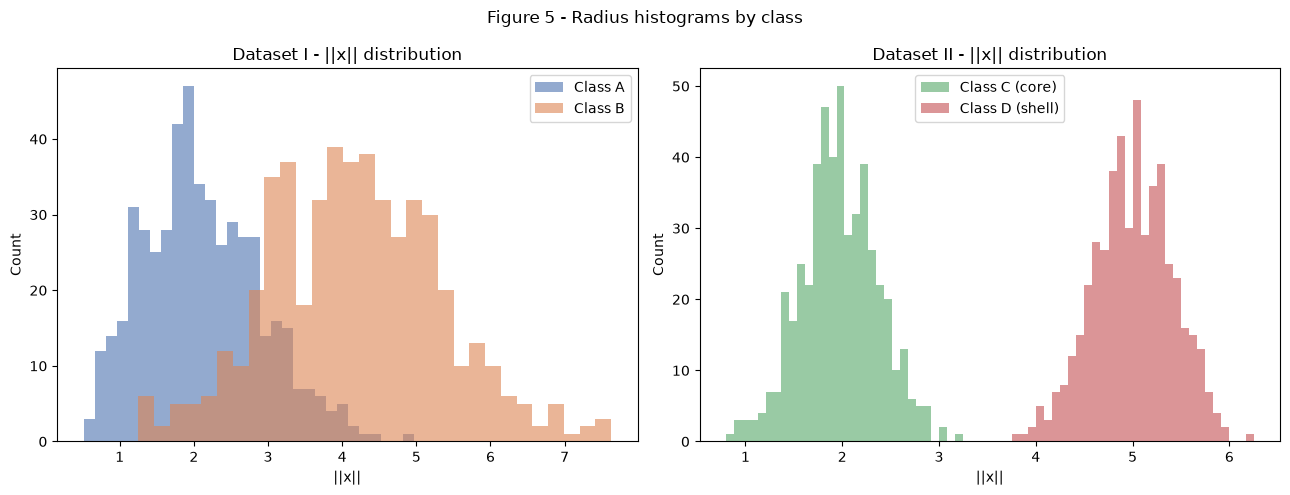

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].hist(np.linalg.norm(class_A, axis=1), bins=30, alpha=0.6, color="#4C72B0", label="Class A")
axes[0].hist(np.linalg.norm(class_B, axis=1), bins=30, alpha=0.6, color="#DD8452", label="Class B")
axes[0].set_title("Dataset I - ||x|| distribution")
axes[0].set_xlabel("||x||"); axes[0].set_ylabel("Count"); axes[0].legend()

axes[1].hist(np.linalg.norm(class_C, axis=1), bins=30, alpha=0.6, color="#55A868", label="Class C (core)")
axes[1].hist(np.linalg.norm(class_D, axis=1), bins=30, alpha=0.6, color="#C44E52", label="Class D (shell)")
axes[1].set_title("Dataset II - ||x|| distribution")
axes[1].set_xlabel("||x||"); axes[1].set_ylabel("Count"); axes[1].legend()

fig.suptitle("Figure 5 - Radius histograms by class")
fig.tight_layout()
plt.show()

## Takeaway
Dataset II's two histograms are cleanly separated (core around 2.0, shell around 5.0) even though the classes are indistinguishable by mean position. A hyperplane classifies based on which side of a flat boundary a point falls on — it has no way to represent "is this point close to or far from the origin," because that's a function of magnitude, not direction. The natural fix is a **non-linear** feature: `||x||^2 = sum(x_i^2)`, i.e. exactly the kind of quadratic function a hidden layer with a non-linear activation can learn but a single linear unit (Perceptron) can't.